In [1]:
import re
import os
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

print(dataset)

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})


Kiểm tra số dòng trong từng tập:

In [3]:
for split in ["train", "validation", "test"]:
    print(f"{split}: {len(dataset[split]):,} dòng")

train: 36,718 dòng
validation: 3,760 dòng
test: 4,358 dòng


Hiển thị 10 dòng đầu tiên:

In [4]:
for i in range(10):
    print(f"{i}: {repr(dataset['train'][i]['text'])}")

0: ''
1: ' = Valkyria Chronicles III = \n'
2: ''
3: ' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . \n'
4: " The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game 

+ WikiText-103 có các dòng tiêu đề và dòng trống. Đây là đặc điểm bình thường của bộ dữ liệu.

Khám phá dữ liệu (EDA)

In [5]:
def analyze_split(split_data):
    texts = split_data["text"]

    total_lines = len(texts)

    empty_lines = sum(
        not text.strip()
        for text in texts
    )

    heading_lines = sum(
        bool(re.match(r"^\s*=+.*=+\s*$", text.strip()))
        for text in texts
    )

    word_counts = [
        len(text.split())
        for text in texts
    ]

    return {
        "Total lines": total_lines,
        "Empty lines": empty_lines,
        "Heading lines": heading_lines,
        "Average words": np.mean(word_counts),
        "Max words": np.max(word_counts),
        "Min words": np.min(word_counts)
    }


eda_results = []

for split in ["train", "validation", "test"]:
    result = analyze_split(dataset[split])
    result["Split"] = split
    eda_results.append(result)

eda_df = pd.DataFrame(eda_results)

display(eda_df)

,Total lines,Empty lines,Heading lines,Average words,Max words,Min words,Split
0,36718,12951,6211,55.882946,699,0,train
1,3760,1299,620,56.884574,429,0,validation
2,4358,1467,706,55.349013,481,0,test


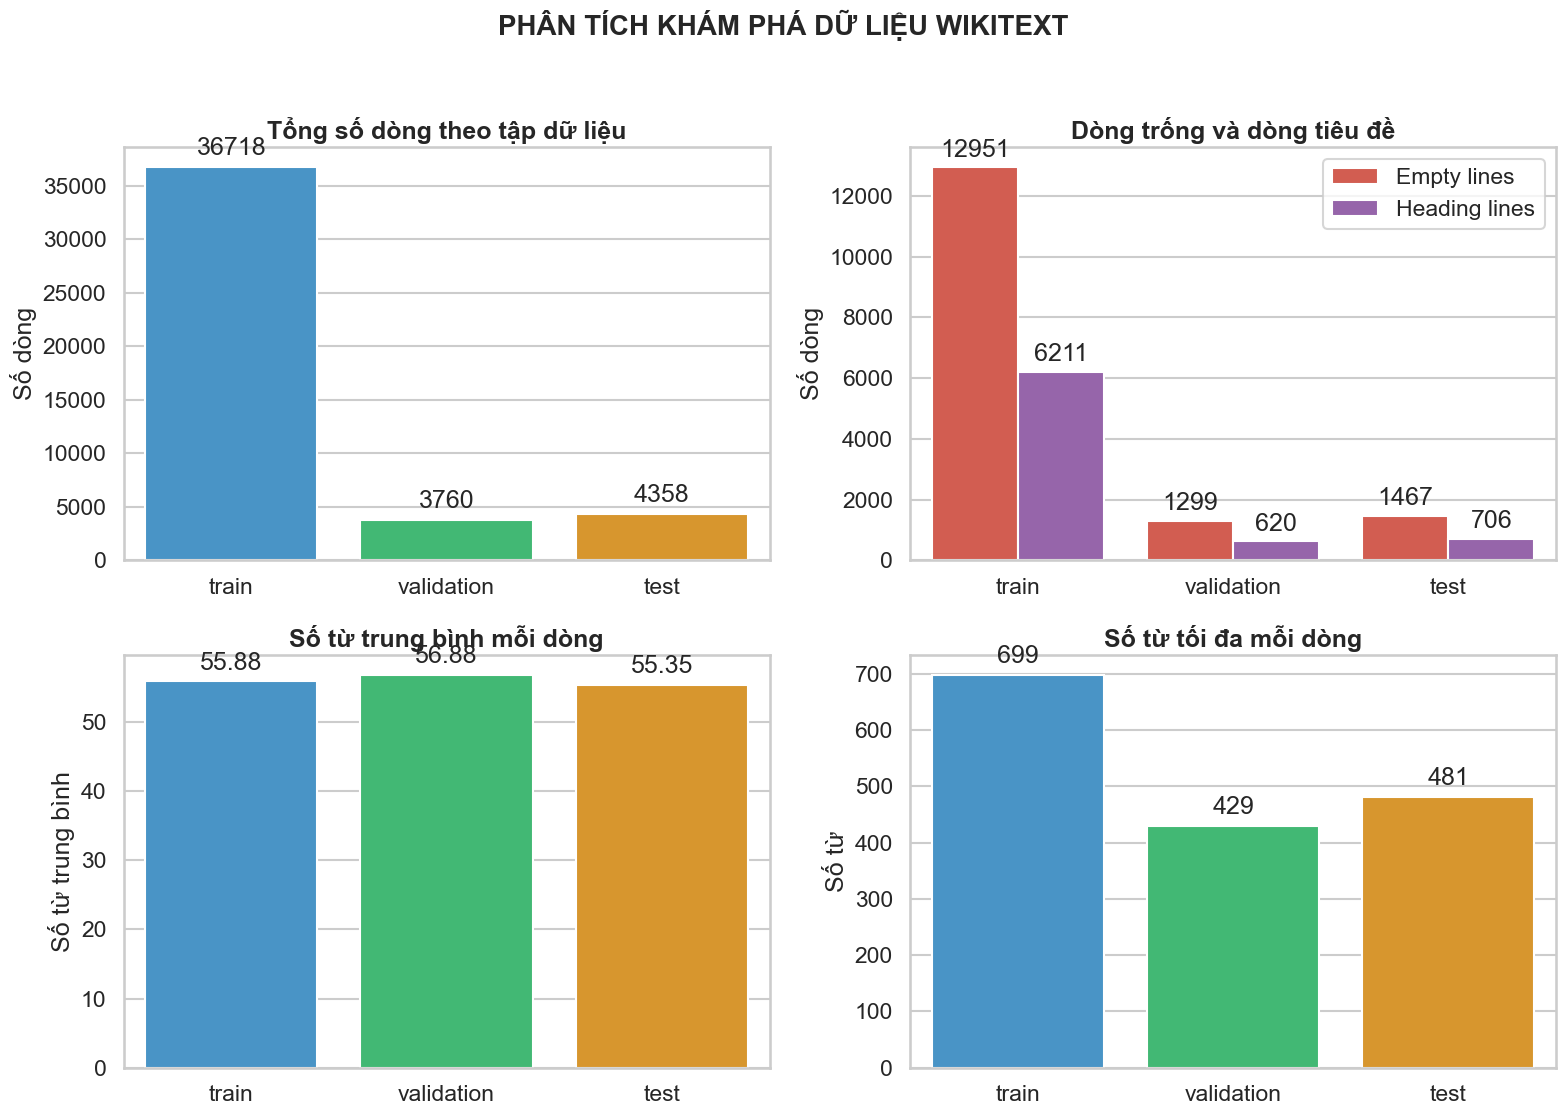

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

colors = ["#3498DB", "#2ECC71", "#F39C12"]
order = ["train", "validation", "test"]

# 1. Tổng số dòng
sns.barplot(
    data=eda_df,
    x="Split",
    y="Total lines",
    hue="Split",
    order=order,
    palette=colors,
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Tổng số dòng theo tập dữ liệu", fontweight="bold")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Số dòng")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f", padding=5)


# 2. Số dòng trống và dòng tiêu đề
eda_melted = eda_df.melt(
    id_vars="Split",
    value_vars=["Empty lines", "Heading lines"],
    var_name="Loại dòng",
    value_name="Số lượng"
)

sns.barplot(
    data=eda_melted,
    x="Split",
    y="Số lượng",
    hue="Loại dòng",
    order=order,
    palette=["#E74C3C", "#9B59B6"],
    ax=axes[0, 1]
)

axes[0, 1].set_title("Dòng trống và dòng tiêu đề", fontweight="bold")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Số dòng")
axes[0, 1].legend(title="")

for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt="%.0f", padding=4)


# 3. Số từ trung bình
sns.barplot(
    data=eda_df,
    x="Split",
    y="Average words",
    hue="Split",
    order=order,
    palette=colors,
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Số từ trung bình mỗi dòng", fontweight="bold")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Số từ trung bình")

for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fmt="%.2f", padding=5)


# 4. Số từ lớn nhất
sns.barplot(
    data=eda_df,
    x="Split",
    y="Max words",
    hue="Split",
    order=order,
    palette=colors,
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Số từ tối đa mỗi dòng", fontweight="bold")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Số từ")

for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt="%.0f", padding=5)


plt.suptitle(
    "PHÂN TÍCH KHÁM PHÁ DỮ LIỆU WIKITEXT",
    fontsize=20,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()

Với Language Modeling, chúng ta không xóa stopword, dấu câu hoặc chuyển từ về gốc, vì mô hình cần học cấu trúc ngôn ngữ tự nhiên.

Ở đây ta giữ nguyên chữ hoa/chữ thường để không làm mất thông tin. Các dòng tiêu đề được giữ nội dung nhưng bỏ ký hiệu = bao quanh.

In [6]:
def clean_text(text):
    text = text.strip()

    if not text:
        return ""

    # Loại ký hiệu heading Wikipedia
    text = re.sub(
        r"^\s*=+\s*(.*?)\s*=+\s*$",
        r"\1",
        text
    )

    # Chuẩn hóa khoảng trắng
    text = re.sub(r"\s+", " ", text)

    return text

Áp dụng cho cả ba tập:

In [7]:
cleaned_data = {}

for split in ["train", "validation", "test"]:

    texts = dataset[split]["text"]

    cleaned_texts = [
        clean_text(text)
        for text in tqdm(texts, desc=f"Cleaning {split}")
    ]

    # Loại dòng trống
    cleaned_texts = [
        text
        for text in cleaned_texts
        if text
    ]

    cleaned_data[split] = cleaned_texts

    print(
        f"{split}: {len(texts):,} -> "
        f"{len(cleaned_texts):,} dòng"
    )

Cleaning train:   0%|          | 0/36718 [00:00<?, ?it/s]

train: 36,718 -> 23,767 dòng


Cleaning validation:   0%|          | 0/3760 [00:00<?, ?it/s]

validation: 3,760 -> 2,461 dòng


Cleaning test:   0%|          | 0/4358 [00:00<?, ?it/s]

test: 4,358 -> 2,891 dòng


In [8]:
for text in cleaned_data["train"][:10]:
    print(text)

Valkyria Chronicles III
Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .
The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers . C

## Word-level Tokenization

ta sử dụng word-level tokenizer đơn giản, tách từ và dấu câu.

In [9]:
TOKEN_PATTERN = re.compile(
    r"\w+(?:['’]\w+)*|[^\w\s]",
    flags=re.UNICODE
)

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

example = "The cat is sleeping."

tokens = tokenize(example)

print("Original:", example)
print("Tokens:", tokens)

Original: The cat is sleeping.
Tokens: ['The', 'cat', 'is', 'sleeping', '.']


Tokenize toàn bộ dữ liệu

In [10]:
tokenized_data = {}

for split in ["train", "validation", "test"]:

    tokenized_data[split] = []

    for text in tqdm(
        cleaned_data[split],
        desc=f"Tokenizing {split}"
    ):
        tokens = tokenize(text)

        # Đánh dấu kết thúc dòng/văn bản
        tokens.append("<eos>")

        tokenized_data[split].extend(tokens)

    print(
        f"{split}: "
        f"{len(tokenized_data[split]):,} tokens"
    )

Tokenizing train:   0%|          | 0/23767 [00:00<?, ?it/s]

train: 2,133,462 tokens


Tokenizing validation:   0%|          | 0/2461 [00:00<?, ?it/s]

validation: 222,830 tokens


Tokenizing test:   0%|          | 0/2891 [00:00<?, ?it/s]

test: 251,166 tokens


Ở phiên bản ban đầu, "eos" đánh dấu kết thúc mỗi dòng không trống. Đây là một quy ước đơn giản để làm baseline, không đồng nghĩa với ranh giới câu thực sự. WikiText gốc không nhất thiết có một câu trên mỗi dòng.

## Xây dựng Vocabulary

Vocabulary chỉ được xây từ tập Train, không sử dụng Validation hoặc Test.

In [12]:
MAX_VOCAB_SIZE = 10000
MIN_FREQ = 2

special_tokens = [
    "<pad>",
    "<unk>",
    "<eos>"
]

counter = Counter(tokenized_data["train"])

word2idx = {
    token: idx
    for idx, token in enumerate(special_tokens)
}

for word, freq in counter.most_common():

    if freq < MIN_FREQ:
        break

    if word in word2idx:
        continue

    if len(word2idx) >= MAX_VOCAB_SIZE:
        break

    word2idx[word] = len(word2idx)

idx2word = {
    idx: word
    for word, idx in word2idx.items()
}

vocab_size = len(word2idx)

PAD_ID = word2idx["<pad>"]
UNK_ID = word2idx["<unk>"]
EOS_ID = word2idx["<eos>"]

print("Vocabulary size:", vocab_size)
print("PAD ID:", PAD_ID)
print("UNK ID:", UNK_ID)
print("EOS ID:", EOS_ID)

Vocabulary size: 10000
PAD ID: 0
UNK ID: 1
EOS ID: 2


Kiểm tra 20 từ xuất hiện nhiều nhất:

In [13]:
print(counter.most_common(20))

[('the', 113161), (',', 102624), ('.', 84291), ('of', 56889), ('and', 50605), ('@', 45600), ('in', 39487), ('to', 39190), ('a', 34269), ('"', 28309), ('<eos>', 23767), ('was', 20985), ("'", 18646), ('The', 17605), ('-', 17337), ('=', 17148), ('s', 14327), ('that', 14135), ('as', 14021), ('on', 13678)]


Chuyển token thành ID

In [14]:
def tokens_to_ids(tokens, word2idx):

    unk_id = word2idx["<unk>"]

    return [
        word2idx.get(token, unk_id)
        for token in tokens
    ]

In [15]:
encoded_data = {}

for split in ["train", "validation", "test"]:

    encoded_data[split] = tokens_to_ids(
        tokenized_data[split],
        word2idx
    )

    print(
        f"{split}: "
        f"{len(encoded_data[split]):,} token IDs"
    )

train: 2,133,462 token IDs
validation: 222,830 token IDs
test: 251,166 token IDs


Kiểm tra một ví dụ

In [16]:
example_tokens = tokenized_data["train"][:20]

example_ids = tokens_to_ids(
    example_tokens,
    word2idx
)

print("Tokens:", example_tokens)
print("IDs:", example_ids)

Tokens: ['Valkyria', 'Chronicles', 'III', '<eos>', 'Senjō', 'no', 'Valkyria', '3', ':', 'Unrecorded', 'Chronicles', '(', 'Japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'Valkyria', 'of']
IDs: [3898, 4409, 850, 2, 1, 127, 3898, 90, 46, 1, 4409, 26, 754, 46, 1, 4, 6478, 5, 3898, 6]


Tính UNK Rate

UNK Rate là tỷ lệ token không có trong vocabulary và bị chuyển thành unk.

In [17]:
def calculate_unk_rate(token_ids, unk_id):

    total = len(token_ids)

    if total == 0:
        return 0

    unk_count = sum(
        token_id == unk_id
        for token_id in token_ids
    )

    return unk_count / total * 100

In [18]:
for split in ["train", "validation", "test"]:

    rate = calculate_unk_rate(
        encoded_data[split],
        UNK_ID
    )

    print(f"{split} UNK Rate: {rate:.2f}%")

train UNK Rate: 9.41%
validation UNK Rate: 11.22%
test UNK Rate: 12.00%


UNK Rate đặc biệt quan trọng đối với word-level modeling. Nếu quá cao, nhiều từ khác nhau sẽ bị mô hình xem như cùng một token

## Tạo Language Modeling Dataset

In [19]:
class LanguageModelingDataset(Dataset):

    def __init__(self, token_ids, context_length=64):

        self.tokens = torch.tensor(
            token_ids,
            dtype=torch.long
        )

        self.context_length = context_length

    def __len__(self):
        return max(
            0,
            (len(self.tokens) - 1)
            // self.context_length
        )

    def __getitem__(self, idx):

        start = idx * self.context_length
        end = start + self.context_length

        x = self.tokens[start:end]

        y = self.tokens[start + 1:end + 1]

        return x, y

## Tạo DataLoader

In [20]:
CONTEXT_LENGTH = 64
BATCH_SIZE = 32

train_dataset = LanguageModelingDataset(
    encoded_data["train"],
    context_length=CONTEXT_LENGTH
)

valid_dataset = LanguageModelingDataset(
    encoded_data["validation"],
    context_length=CONTEXT_LENGTH
)

test_dataset = LanguageModelingDataset(
    encoded_data["test"],
    context_length=CONTEXT_LENGTH
)

In [21]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

Kiểm tra kích thước:

In [22]:
X, Y = next(iter(train_loader))

print("X shape:", X.shape)
print("Y shape:", Y.shape)

print("Vocabulary size:", vocab_size)

X shape: torch.Size([32, 64])
Y shape: torch.Size([32, 64])
Vocabulary size: 10000


Kiểm tra đầu vào và mục tiêu

In [23]:
X, Y = next(iter(train_loader))

x_tokens = [
    idx2word[idx]
    for idx in X[0][:15].tolist()
]

y_tokens = [
    idx2word[idx]
    for idx in Y[0][:15].tolist()
]

print("Input:")
print(x_tokens)

print("\nTarget:")
print(y_tokens)

assert torch.equal(
    X[0, 1:],
    Y[0, :-1]
), "Input và target chưa dịch đúng một token!"

print("\nKiểm tra Next-token Prediction: OK")

Input:
['such', 'as', 'the', '<unk>', '<unk>', 'and', 'the', 'HIV', '<unk>', 'protein', 'have', 'been', 'successfully', '<unk>', 'in']

Target:
['as', 'the', '<unk>', '<unk>', 'and', 'the', 'HIV', '<unk>', 'protein', 'have', 'been', 'successfully', '<unk>', 'in', '<unk>']

Kiểm tra Next-token Prediction: OK


Tổng hợp kết quả preprocessing

In [24]:
summary = []

for split in ["train", "validation", "test"]:

    summary.append({
        "Split": split,
        "Clean lines": len(cleaned_data[split]),
        "Tokens": len(tokenized_data[split]),
        "UNK Rate (%)": round(
            calculate_unk_rate(
                encoded_data[split],
                UNK_ID
            ),
            2
        ),
        "Context Length": CONTEXT_LENGTH,
        "Vocabulary Size": vocab_size,
        "Batch Size": BATCH_SIZE
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Split,Clean lines,Tokens,UNK Rate (%),Context Length,Vocabulary Size,Batch Size
0,train,23767,2133462,9.41,64,10000,32
1,validation,2461,222830,11.22,64,10000,32
2,test,2891,251166,12.00,64,10000,32


Lưu vocabulary và cấu hình chung

In [25]:
os.makedirs("data/processed", exist_ok=True)

with open(
    "data/processed/word2idx.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        word2idx,
        f,
        ensure_ascii=False
    )

config = {
    "dataset": "wikitext-103-raw-v1",
    "tokenizer": "regex_word_level",
    "lowercase": False,
    "max_vocab_size": MAX_VOCAB_SIZE,
    "min_freq": MIN_FREQ,
    "vocab_size": vocab_size,
    "context_length": CONTEXT_LENGTH,
    "batch_size": BATCH_SIZE,
    "pad_id": PAD_ID,
    "unk_id": UNK_ID,
    "eos_id": EOS_ID,
    "seed": SEED
}

with open(
    "data/processed/config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=4)

summary_df.to_csv(
    "data/processed/data_summary.csv",
    index=False
)

print("Đã lưu vocabulary, config và thống kê.")

Đã lưu vocabulary, config và thống kê.


In [26]:
import torch

torch.save(
    encoded_data["train"],
    "data/processed/train.pt"
)

torch.save(
    encoded_data["validation"],
    "data/processed/valid.pt"
)

torch.save(
    encoded_data["test"],
    "data/processed/test.pt"
)

print("Đã lưu dữ liệu cho 3 mô hình!")

Đã lưu dữ liệu cho 3 mô hình!
